# SCRUM-29 — Text Mining Evaluation & Signal Correlation

**Owner:** Burra Vijay Krishna · **Sprint:** SCRUM Sprint 2 (Review 2) · **Unit 3, Method 2 (Text Mining)**

SCRUM-28 (Ashwin) gave every usable YouTube comment a sentiment score with **VADER**, and found topics. This notebook checks that work and answers two questions:

1. **Is the sentiment right?** Score VADER and the alternatives against reference labels on the same 100 comments.
2. **Do comments come before searches?** Check, week by week, whether comment activity rises *before* Google search interest does (the "early signal" idea from Review 1).

Builds on: SCRUM-21 (`processed/master_dataset.csv`), SCRUM-23 (`text_corpus.csv`) and SCRUM-28 (`text_sentiment_comments.csv`, `text_sentiment_spotcheck.csv`).
All the code is in `src/evaluate_text_mining.py` and tested in `tests/test_evaluate_text_mining.py`; this notebook runs it step by step.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
import config
import evaluate_text_mining as etm

paths = config.Paths.from_root(ROOT)
PROC = paths.processed_dir
FIG = ROOT / 'docs' / 'figures'
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)
%matplotlib inline

## 1. The reference labels

The 100 comments are the same random sample Ashwin used for his SCRUM-28 spot check, so the results can be compared with his.

**How they were labelled:** each comment got one of positive / neutral / negative / unclear, using the written rules in the labelling sheet (the same rules as Ashwin's AI review). Clear praise is positive, complaints and sarcasm are negative, questions and plain facts are neutral, and greetings and off-topic jokes are unclear.

- A few comments were labelled **by hand** (`label_source = human`).
- The rest were labelled by **a second AI review (Claude)** (`label_source = AI (Claude), not human`).
- Neither saw VADER's or the SCRUM-28 AI review's labels. The `note` column marks the three comments where that was not fully true.

**Be honest about this:** most reference labels come from an AI reader, so the scores below show *agreement with a careful AI reader*, not accuracy against human judgement.

In [2]:
labelled = etm.load_labelled(paths)
pd.crosstab(labelled['label_source'], labelled['reference_label'], margins=True, margins_name='total')

reference_label,negative,neutral,positive,unclear,total
label_source,,,,,
"AI (Claude), not human",29,25,34,6,94
human,1,1,3,1,6
total,30,26,37,7,100


## 2. Comparing the methods (template slide 13)

Every method labels the same comments, and is scored against the reference labels. Comments marked *unclear* are left out.

| Method | What it is |
|---|---|
| **VADER** | the project's method: a sentiment word list built for social media (SCRUM-28) |
| **TextBlob** | a second word-list method, on the same cleaned text with the same ±0.05 cut-offs |
| **AI review** | Ashwin's AI labels from the SCRUM-28 spot check (its "unclear" counts as a miss) |
| **Always positive** | a no-skill baseline: positive is the most common label in the whole corpus |

**Metrics:**
- **Accuracy:** share of comments labelled the same as the reference.
- **Macro-F1:** the average of the F1 scores of the three classes, so the rare negative class counts as much as positive.
- **Negative recall:** share of the complaints the method catches.
- **Cohen's kappa:** agreement after removing what chance alone would give (0 = chance, 1 = perfect).

In [3]:
all_labels, all_confusion = etm.compare_methods(labelled, 'all labels (human + AI review)')
view = all_labels.assign(**{'accuracy (95% CI)': all_labels.apply(
    lambda r: f"{r.accuracy:.0%} ({r.accuracy_ci95_low:.0%}-{r.accuracy_ci95_high:.0%})", axis=1)})
view[['method', 'comments', 'accuracy (95% CI)', 'macro_f1', 'negative_recall', 'cohen_kappa']].round(2)

,method,comments,accuracy (95% CI),macro_f1,negative_recall,cohen_kappa
0,VADER (project method),93,49% (40%-59%),0.47,0.27,0.22
1,TextBlob,93,42% (32%-52%),0.37,0.10,0.13
2,AI review (SCRUM-28 spot check),93,80% (70%-87%),0.83,0.70,0.70
3,Always positive (baseline),93,40% (30%-50%),0.19,0.00,0.00


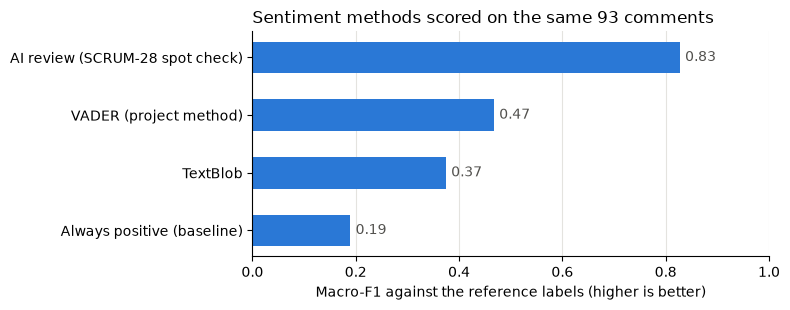

In [4]:
order = all_labels.sort_values('macro_f1')
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.barh(order['method'], order['macro_f1'], color='#2a78d6', height=0.55)
for y, v in enumerate(order['macro_f1']):
    ax.text(v + 0.01, y, f'{v:.2f}', va='center', color='#52514e', fontsize=10)
ax.set_xlim(0, 1)
ax.set_xlabel('Macro-F1 against the reference labels (higher is better)')
ax.set_title(f"Sentiment methods scored on the same {order['comments'].iloc[0]} comments", loc='left', fontsize=12)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', color='#e4e3df', linewidth=0.8)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIG / 'scrum29_method_comparison.png', dpi=150)
plt.show()

**What the table says:**
- **VADER is better than the baseline and better than TextBlob**, so SCRUM-28 picked the better of the two word-list tools.
- But VADER agrees with the reference only about **half the time**, and it **catches only about a quarter of the complaints**.
- TextBlob is worse still, especially on complaints.
- The AI review agrees with the reference much more often (see section 4).

## 3. Where VADER goes wrong

Rows: the reference label. Columns: VADER's label.

In [5]:
rated = labelled[labelled['reference_label'].isin(etm.CLASSES)]
pd.crosstab(rated['reference_label'], rated['vader_label']).reindex(index=etm.CLASSES, columns=etm.CLASSES, fill_value=0)

vader_label,positive,neutral,negative
reference_label,,,
positive,26,9,2
neutral,12,12,2
negative,15,7,8


The complaints VADER missed, with its score (from −1 to +1):

In [6]:
scores = pd.read_csv(PROC / 'text_sentiment_comments.csv', usecols=['product_id', 'comment_id', 'sentiment_compound'],
                     dtype={'comment_id': str})
complaints = rated[rated['reference_label'] == 'negative'].merge(scores, on=['product_id', 'comment_id'], how='left')
missed = complaints[complaints['vader_label'] != 'negative']
print(f"Complaints in the reference: {len(complaints)}; VADER caught {len(complaints) - len(missed)} and missed {len(missed)} "
      f"({(missed['vader_label'] == 'positive').sum()} read as positive, {(missed['vader_label'] == 'neutral').sum()} as neutral)")
missed[['text', 'vader_label', 'sentiment_compound']].head(10)

Complaints in the reference: 30; VADER caught 8 and missed 22 (15 read as positive, 7 as neutral)


,text,vader_label,sentiment_compound
1,Price me kuch jyada hi hag diya😂😂,positive,0.7003
2,Charger enga vanguvinga online la charger varathu orginala 😂😂😂😂😂,positive,0.7003
3,Nothing extremely uncomfortable in your hands . Not at all recommended,positive,0.2044
5,"Oh, we’re here already… I concider myself a bit of a tech nerd but even I’m starting to kind of forget about these y...",positive,0.1583
6,Bhai ko bhi apna ghar chalana he yaar ..... To tareef to karna padegi...😂😂😂,positive,0.7003
7,"while it looks good, the periscope camera might be unnecessary, as the sensor doesn't seem to be very large either",positive,0.4404
8,Release an upper mid-range specs ($450) with flagship killer theme ($600) Then let us call it a flagship & sell it f...,positive,0.1027
11,"""Snapdragon 6 series"" and ""Good performance"" should not be said in the same line.",positive,0.4404
12,Bro yeh sab toh infinix gt 30 main bhi hai,positive,0.2732
14,Sounds like Oneplus is the new IQOO 🥲,positive,0.3612


Two patterns explain most of the misses. VADER is a list of **English** words and emojis, each with a score:
- **Sarcasm and laughing emojis read as happy.** 😂, 🙂 and ✅ carry positive scores, so jokes that are really complaints score high:
  - "Nothing phone 3 - im flagship ..trust me bro 🙂" scores **+0.75**;
  - "Hammer of metal ❌❌ Hammer of fiber ✅✅😅😅" scores **+0.61**.
- **Hinglish and other languages are often scored exactly 0 (neutral).** VADER doesn't know the words: "Ise se aacha 40k mey reno 14 pro ley loo" (better to buy the Reno 14 Pro instead) and "S26 dekhe ho kabhi?" both score 0. Over the 33 regional-language comments, VADER matched the reference only 10 times.

## 4. Can we trust the AI spot check?

Ashwin's AI review agrees with the reference labels on about 80% of the comments, with kappa ≈ 0.70 ("substantial agreement"). So two separate AI readings mostly agree, and his SCRUM-28 finding (VADER agrees with the AI review only ~55% of the time) holds up.

**Caution:** both AI reviews may come from the same kind of model. Their agreement can therefore be higher than two different people would show, which is why real human labels still matter.

## 5. Human labels only (for transparency)

Only a few comments were labelled by hand, so these numbers are **too few to judge**. They are shown so that nothing is hidden.

In [7]:
human_only, _ = etm.compare_methods(labelled[labelled['label_source'] == 'human'], 'human labels only')
human_only[['method', 'comments', 'accuracy', 'macro_f1', 'cohen_kappa']].round(2)

,method,comments,accuracy,macro_f1,cohen_kappa
0,VADER (project method),5,0.4,0.19,-0.25
1,TextBlob,5,0.2,0.13,-0.25
2,AI review (SCRUM-28 spot check),5,0.6,0.60,0.41
3,Always positive (baseline),5,0.6,0.25,0.00


## 6. Do comments come before searches?

Review 1 said online buzz comes **before** the demand peak. Here is a direct test.

- For every phone, take **full weeks** (Monday to Sunday) inside the Trends window: the average search interest, the number of comments posted, and the average VADER score (only weeks with at least 5 scored comments).
- Put each phone on the same scale (z-scores within the phone), so that big and small phones count equally.
- Then ask: is **this week's change in searches** related to the comment signal **k weeks earlier**? Spearman correlation is pooled over all phones.

Lag +1 means "comments one week before the search change", and lag −1 means one week after.

In [8]:
master = pd.read_csv(ROOT / 'processed' / 'master_dataset.csv',
                     usecols=['product_id', 'date', 'search_interest', 'comments_published'])
comments = pd.read_csv(PROC / 'text_sentiment_comments.csv',
                       usecols=['product_id', 'comment_id', 'published_at', 'sentiment_compound'], dtype={'comment_id': str})
weekly = etm.weekly_signals(master, comments)
print(f"{len(weekly):,} phone-weeks: {weekly['product_id'].nunique()} phones x "
      f"{weekly.groupby('product_id').size().iloc[0]} full weeks; {int(weekly['sentiment'].notna().sum())} weeks have a usable sentiment mean")
lags = etm.lead_lag(weekly)
lags[['meaning', 'lag_weeks', 'spearman_rho', 'p_value', 'pairs', 'phones']].round(3)

2,220 phone-weeks: 60 phones x 37 full weeks; 534 weeks have a usable sentiment mean


,meaning,lag_weeks,spearman_rho,p_value,pairs,phones
0,change in comments posted,-2,0.036,0.107,2040,60
1,change in comments posted,-1,0.029,0.183,2100,60
2,change in comments posted,0,0.128,0.000,2160,60
3,change in comments posted,1,0.034,0.119,2100,60
4,change in comments posted,2,-0.017,0.450,2040,60
5,mean VADER score,-2,0.058,0.195,507,47
6,mean VADER score,-1,-0.025,0.573,512,47
7,mean VADER score,0,0.078,0.078,519,47
8,mean VADER score,1,-0.071,0.113,505,47
9,mean VADER score,2,-0.125,0.006,479,45


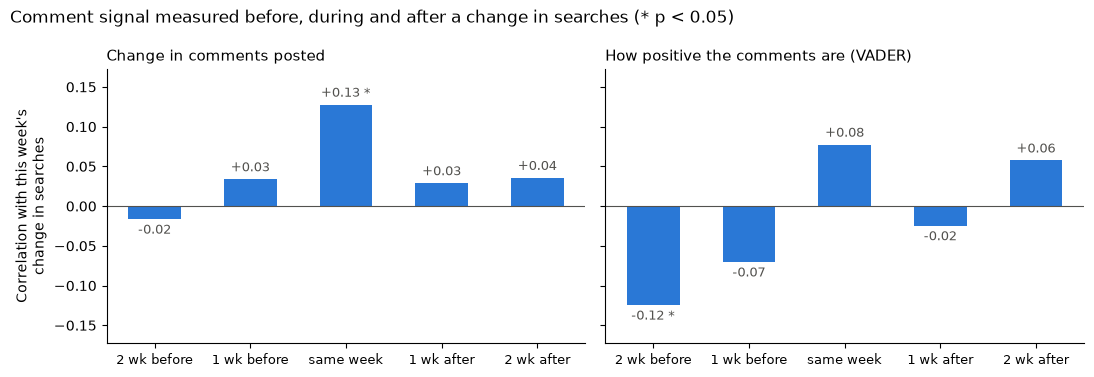

In [9]:
names = {-2: '2 wk after', -1: '1 wk after', 0: 'same week', 1: '1 wk before', 2: '2 wk before'}
reach = lags['spearman_rho'].abs().max() * 1.35  # room for the value labels above and below the bars
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
axes[0].set_ylim(-reach, reach)
for ax, (signal, title) in zip(axes, [('comments_change', 'Change in comments posted'),
                                      ('sentiment', 'How positive the comments are (VADER)')]):
    part = lags[lags['signal'] == signal].sort_values('lag_weeks', ascending=False)
    ax.bar([names[k] for k in part['lag_weeks']], part['spearman_rho'], color='#2a78d6', width=0.55)
    for x, (rho, p) in enumerate(zip(part['spearman_rho'], part['p_value'])):
        ax.text(x, rho + (0.006 if rho >= 0 else -0.006), f"{rho:+.2f}{' *' if p < 0.05 else ''}",
                ha='center', va='bottom' if rho >= 0 else 'top', fontsize=9, color='#52514e')
    ax.axhline(0, color='#52514e', linewidth=0.8)
    ax.set_title(title, loc='left', fontsize=11)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='x', labelsize=9)
axes[0].set_ylabel("Correlation with this week's\nchange in searches")
fig.suptitle('Comment signal measured before, during and after a change in searches (* p < 0.05)', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
fig.savefig(FIG / 'scrum29_lead_lag.png', dpi=150)
plt.show()

**What it says:**
- **Comment activity moves in the same week as searches** (ρ ≈ +0.13, clearly not chance). One or two weeks earlier, or later, the link is close to zero.
- **Sentiment hardly relates to searches at all.** The one small negative value two weeks earlier is probably chance: we ran 10 tests, and weeks of the same phone are not independent.
- So **comments are not an early warning in our data**, and the "7–14 days earlier" idea from Review 1 is not supported here. This fits what the team found elsewhere:
  - Ashwin (SCRUM-28): phones with more positive comments have slightly higher average search interest (ρ = 0.28);
  - Mounik (SCRUM-24): daily sentiment and topic features relate to the *level* of search interest (up to r = 0.26), but to *surges* only very weakly (|r| ≤ 0.07).

## 7. What this means for the business

| Evidence | Recommended action | Benefit / limitation |
|---|---|---|
| VADER misses about 3 of 4 complaints: sarcasm and 😂 read as positive, and Hinglish is often scored 0 | Treat the sentiment score as a rough signal. Read the negative comments themselves before acting, and move to a model that understands Hinglish (for example a multilingual transformer) | Fewer surprises from hidden complaints; needs more compute and some labelled data |
| Comment activity rises **in the same week** as searches, not before | Use comment activity to **confirm** a surge this week, and use the search trend (Method 1) for the **early** warning | Faster confirmation than waiting for sales data; no extra lead time from comments |
| The two AI reviews agree ~80% | AI labelling can speed up building a test set, but check a sample by hand | Saves time; AI readers may share the same blind spots |

## 8. Limitations

- **The reference labels are mostly AI labels.** More hand labels would make the evaluation stronger.
- **100 comments is small:** the 95% interval on accuracy is about ±10 points.
- **The comments are a sample:** they come from the top videos per phone, collected on 3–4 October, so older comments are under-represented.
- **Pooled correlations treat each phone-week separately**, so the p-values are a bit optimistic.
- **VADER and TextBlob are English word lists.** They are expected to struggle with Hinglish, so the comparison shows the limit of this *kind* of method.

**Rebuild:** `python src/evaluate_text_mining.py` (writes `data/processed/text_eval_method_comparison.csv`, `text_eval_confusion.csv`, `text_signal_lead_lag.csv`) · **Test:** `python -m pytest tests/test_evaluate_text_mining.py`

In [10]:
assert etm.main(paths) == 0  # the same run as python src/evaluate_text_mining.py, writes the three CSVs

                     reference                          method  comments  accuracy  macro_f1  negative_recall  cohen_kappa
all labels (human + AI review)          VADER (project method)        93     0.495     0.468            0.267        0.219
all labels (human + AI review)                        TextBlob        93     0.419     0.375            0.100        0.129
all labels (human + AI review) AI review (SCRUM-28 spot check)        93     0.796     0.828            0.700        0.702
all labels (human + AI review)      Always positive (baseline)        93     0.398     0.190            0.000        0.000
             human labels only          VADER (project method)         5     0.400     0.190            0.000       -0.250
             human labels only                        TextBlob         5     0.200     0.133            0.000       -0.250
             human labels only AI review (SCRUM-28 spot check)         5     0.600     0.600            1.000        0.412
             hum